In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Retail Sales Analysis Project Started!")
print("Libraries imported successfully!")

Retail Sales Analysis Project Started!
Libraries imported successfully!


In [3]:
import pandas as pd

df = pd.read_csv('/content/retail_sales_dataset.csv')

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape:
(1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [5]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [6]:
print("Number of Duplicate Rows:")
print(df.duplicated().sum())

Number of Duplicate Rows:
0


In [7]:
print("Statistical Summary of Retail Sales Dataset:")
df.describe()

Statistical Summary of Retail Sales Dataset:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [8]:
print("Gender-wise Customer Count:")

print(df["Gender"].value_counts())

Gender-wise Customer Count:
Gender
Female    510
Male      490
Name: count, dtype: int64


In [9]:
print("Total Sales by Product Category:")

category_sales = df.groupby("Product Category")["Total Amount"].sum()

print(category_sales)

Total Sales by Product Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


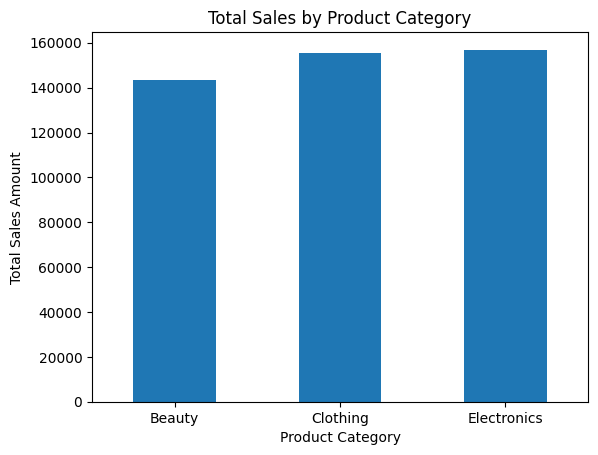

In [10]:
category_sales = df.groupby("Product Category")["Total Amount"].sum()

category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)

plt.show()

In [11]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month

monthly_sales = df.groupby("Month")["Total Amount"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


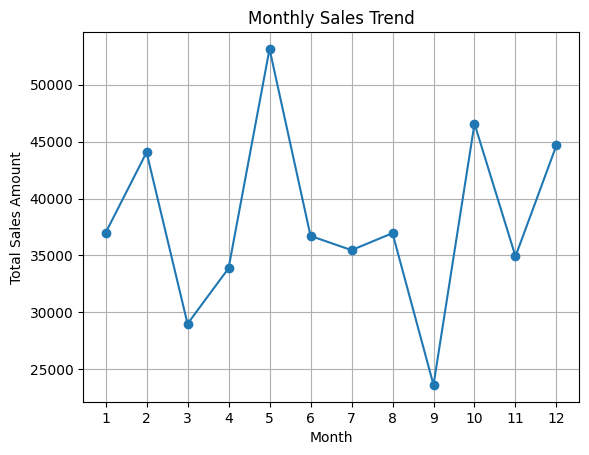

In [12]:
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [13]:
category_quantity = df.groupby("Product Category")["Quantity"].sum()

print("Total Quantity Sold by Category:")
print(category_quantity)

print("\nBest-Selling Category:")
print(category_quantity.idxmax())

Total Quantity Sold by Category:
Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64

Best-Selling Category:
Clothing


In [14]:
print("Customer Age Statistics:")
print(df["Age"].describe())

Customer Age Statistics:
count    1000.00000
mean       41.39200
std        13.68143
min        18.00000
25%        29.00000
50%        42.00000
75%        53.00000
max        64.00000
Name: Age, dtype: float64


In [15]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 100],
    labels=["Below 20", "21-30", "31-40", "41-50", "Above 50"]
)

age_sales = df.groupby("Age Group", observed=False)["Total Amount"].sum()

print("Total Sales by Age Group:")
print(age_sales)

Total Sales by Age Group:
Age Group
Below 20     34730
21-30        98215
31-40        95950
41-50        93795
Above 50    133310
Name: Total Amount, dtype: int64


In [16]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print("Total Sales by Gender:")
print(gender_sales)

print("\nHighest Sales Contribution:")
print(gender_sales.idxmax())

Total Sales by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

Highest Sales Contribution:
Female


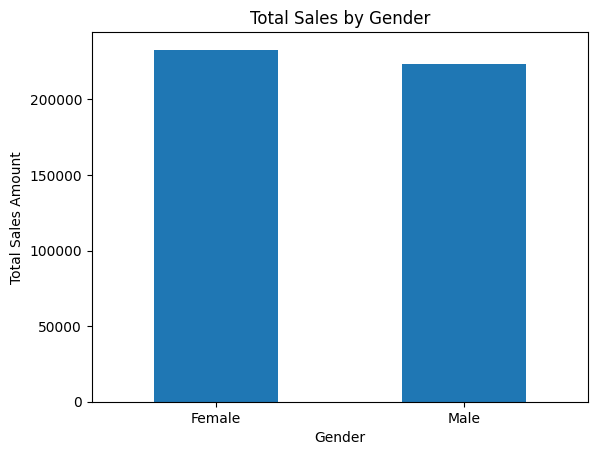

In [17]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)

plt.show()

In [18]:
average_price = df.groupby("Product Category")["Price per Unit"].mean()

print("Average Price per Unit by Category:")
print(average_price)

print("\nHighest Average Price Category:")
print(average_price.idxmax())

Average Price per Unit by Category:
Product Category
Beauty         184.055375
Clothing       174.287749
Electronics    181.900585
Name: Price per Unit, dtype: float64

Highest Average Price Category:
Beauty


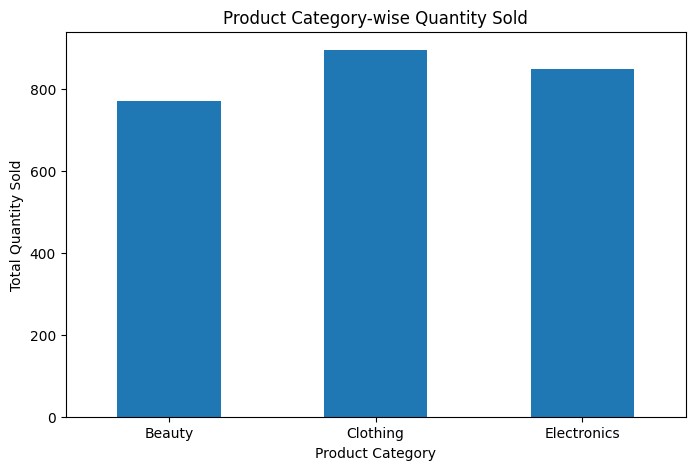

In [19]:
category_quantity = df.groupby("Product Category")["Quantity"].sum()

plt.figure(figsize=(8, 5))

category_quantity.plot(kind="bar")

plt.title("Product Category-wise Quantity Sold")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)

plt.show()

In [20]:
correlation = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
].corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                     Age  Quantity  Price per Unit  Total Amount
Age             1.000000 -0.023737       -0.038423     -0.060568
Quantity       -0.023737  1.000000        0.017501      0.373707
Price per Unit -0.038423  0.017501        1.000000      0.851925
Total Amount   -0.060568  0.373707        0.851925      1.000000


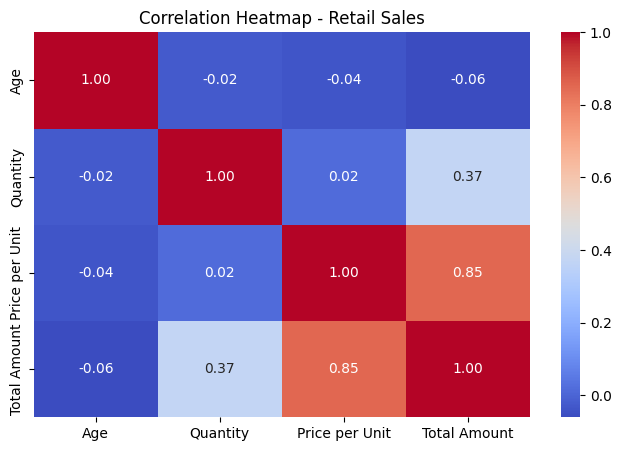

In [21]:

plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap - Retail Sales")
plt.show()

In [22]:
daily_sales = df.groupby("Date")["Total Amount"].sum()

print("Top 5 Days with Highest Sales:")
print(daily_sales.sort_values(ascending=False).head(5))

Top 5 Days with Highest Sales:
Date
2023-05-23    8455
2023-05-16    7260
2023-06-24    6220
2023-02-17    5890
2023-08-05    5205
Name: Total Amount, dtype: int64


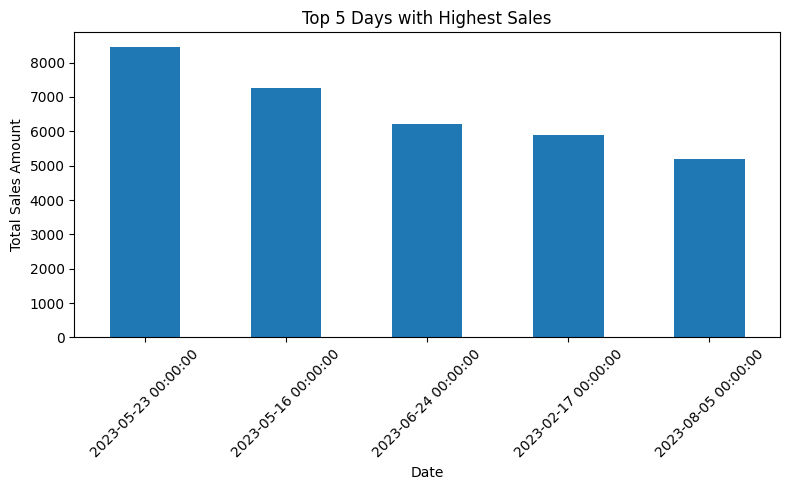

In [23]:
top_5_days = daily_sales.sort_values(ascending=False).head(5)

top_5_days.plot(kind="bar", figsize=(8, 5))

plt.title("Top 5 Days with Highest Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [24]:
print("===== RETAIL SALES ANALYSIS REPORT =====")

print("\n1. Total Transactions:")
print(df["Transaction ID"].nunique())

print("\n2. Total Revenue:")
print(df["Total Amount"].sum())

print("\n3. Average Transaction Amount:")
print(round(df["Total Amount"].mean(), 2))

print("\n4. Best-Selling Product Category:")
print(df.groupby("Product Category")["Quantity"].sum().idxmax())

print("\n5. Highest Revenue Category:")
print(df.groupby("Product Category")["Total Amount"].sum().idxmax())

print("\n6. Total Quantity Sold:")
print(df["Quantity"].sum())

print("\n7. Average Customer Age:")
print(round(df["Age"].mean(), 2))

===== RETAIL SALES ANALYSIS REPORT =====

1. Total Transactions:
1000

2. Total Revenue:
456000

3. Average Transaction Amount:
456.0

4. Best-Selling Product Category:
Clothing

5. Highest Revenue Category:
Electronics

6. Total Quantity Sold:
2514

7. Average Customer Age:
41.39
